# WallVoice24BD Interactive Visualization Dashboard

This notebook provides interactive visualization of the WallVoice24BD project results, including:
- Dataset overview and statistics
- Model performance comparison
- Interactive confusion matrices
- Sample image gallery
- Feature visualization

All plots are interactive - you can zoom, pan, and explore the data.

In [1]:
# Install required packages if not already installed
# !pip install plotly ipywidgets pandas numpy matplotlib seaborn pillow scikit-learn joblib

In [3]:
import sys
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import plotly.graph_objects as go
import plotly.express as px
from plotly.subplots import make_subplots
from IPython.display import display, HTML
import ipywidgets as widgets
from ipywidgets import interact, interactive, fixed, interact_manual, IntSlider, Dropdown, VBox

# Set up paths
ROOT = Path.cwd()
METADATA_PATH = ROOT / "metadata" / "images.csv"
OUTPUTS_DIR = ROOT / "outputs"
FEATURES_DIR = ROOT / "features"
SPLITS_DIR = ROOT / "splits"
MODELS_DIR = ROOT / "models"

# Area codes mapping
AREA_CODES = {
    "DU-Shahbagh": "DUS",
    "Dhanmondi": "DMD",
    "Azimpur-Nilkhet": "AZN",
    "BaileyRoad-Viqarunnisa": "BRV",
    "Buet-Palashi": "BUP",
    "Mirpur-Uttara-Tejgaon": "MUT",
}
CODE_TO_AREA = {code: area for area, code in AREA_CODES.items()}

# Set plotting style
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 8)

print("Libraries imported successfully!")

Libraries imported successfully!


## 1. Load Dataset and Results

In [4]:
# Load metadata
metadata_df = pd.read_csv(METADATA_PATH, dtype=str, keep_default_na=False)
metadata_df['relative_path'] = metadata_df['relative_path'].str.replace('\\', '/', regex=False)
print(f"Loaded {len(metadata_df)} images from metadata")

# Load model selection results
model_selection_path = OUTPUTS_DIR / "model-selection.json"
if model_selection_path.exists():
    with open(model_selection_path, 'r') as f:
        model_selection = json.load(f)
    print("Loaded model selection results")
else:
    print("Model selection results not found. Run training first.")
    model_selection = None

# Load evaluation results
evaluation_path = OUTPUTS_DIR / "evaluation.json"
if evaluation_path.exists():
    with open(evaluation_path, 'r') as f:
        evaluation = json.load(f)
    print("Loaded evaluation results")
else:
    print("Evaluation results not found. Run evaluation first.")
    evaluation = None

# Load splits
splits = {}
for split_name in ['train', 'val', 'test']:
    split_path = SPLITS_DIR / f"{split_name}.csv"
    if split_path.exists():
        splits[split_name] = pd.read_csv(split_path, dtype=str, keep_default_na=False)
        print(f"Loaded {split_name} split: {len(splits[split_name])} images")
    else:
        print(f"{split_name} split not found")

Loaded 1225 images from metadata
Loaded model selection results
Loaded evaluation results
Loaded train split: 854 images
Loaded val split: 186 images
Loaded test split: 185 images


## 2. Dataset Overview (Interactive)

In [5]:
# Count images by area
area_counts = metadata_df['area'].value_counts().reset_index()
area_counts.columns = ['Area', 'Count']
area_counts['Area Code'] = area_counts['Area'].map(AREA_CODES)

# Create interactive bar chart
fig = px.bar(
    area_counts,
    x='Area',
    y='Count',
    color='Area',
    title='WallVoice24BD Dataset: Images per Collection Area',
    text='Count',
    hover_data=['Area Code']
)
fig.update_layout(
    xaxis_title="Collection Area",
    yaxis_title="Number of Images",
    showlegend=False,
    height=500
)
fig.show()

# Display summary table
print("\nDataset Summary:")
print(f"Total images: {len(metadata_df)}")
print(f"Number of areas: {len(area_counts)}")
display(area_counts.style.hide(axis='index'))


Dataset Summary:
Total images: 1225
Number of areas: 6


Area,Count,Area Code
DU-Shahbagh,428,DUS
Dhanmondi,312,DMD
Azimpur-Nilkhet,172,AZN
BaileyRoad-Viqarunnisa,136,BRV
Buet-Palashi,90,BUP
Mirpur-Uttara-Tejgaon,87,MUT


## 3. Data Split Distribution (Interactive)

In [6]:
if splits:
    # Create split distribution data
    split_data = []
    for split_name, split_df in splits.items():
        counts = split_df['label'].value_counts()
        for label, count in counts.items():
            split_data.append({
                'Split': split_name.capitalize(),
                'Area Code': label,
                'Area': CODE_TO_AREA.get(label, label),
                'Count': count
            })
    
    split_df_plot = pd.DataFrame(split_data)
    
    # Create grouped bar chart
    fig = px.bar(
        split_df_plot,
        x='Area Code',
        y='Count',
        color='Split',
        barmode='group',
        title='Data Split Distribution by Area',
        text='Count',
        hover_data=['Area']
    )
    fig.update_layout(
        xaxis_title="Area Code",
        yaxis_title="Number of Images",
        height=500
    )
    fig.show()
    
    # Display split summary
    split_summary = split_df_plot.groupby('Split')['Count'].sum().reset_index()
    split_summary['Percentage'] = (split_summary['Count'] / split_summary['Count'].sum() * 100).round(1)
    print("\nSplit Summary:")
    display(split_summary.style.hide(axis='index'))
else:
    print("Splits not available")


Split Summary:


Split,Count,Percentage
Test,185,15.100000
Train,854,69.700000
Val,186,15.200000


## 4. Model Performance Comparison (Interactive)

In [7]:
if model_selection:
    # Extract KNN results
    knn_results = []
    for result in model_selection.get('results', []):
        knn_results.append({
            'Extractor': result['extractor'].upper(),
            'Accuracy': result['val_metrics']['accuracy'],
            'Macro-F1': result['val_metrics']['macro_f1'],
            'Weighted-F1': result['val_metrics']['weighted_f1'],
            'CV Macro-F1': result['cv_macro_f1'],
            'CV Std': result['cv_std_macro_f1']
        })
    
    # Extract baseline results
    baseline_results = []
    baseline_names = {
        'logistic_regression_balanced': 'Logistic Reg (Balanced)',
        'linear_svm_balanced': 'Linear SVM (Balanced)',
        'dummy_most_frequent': 'Dummy (Most Frequent)'
    }
    for key, metrics in model_selection.get('baselines', {}).items():
        baseline_results.append({
            'Extractor': baseline_names.get(key, key),
            'Accuracy': metrics['accuracy'],
            'Macro-F1': metrics['macro_f1'],
            'Weighted-F1': metrics['weighted_f1'],
            'CV Macro-F1': None,
            'CV Std': None
        })
    
    all_results = pd.DataFrame(knn_results + baseline_results)
    
    # Create interactive comparison chart
    fig = make_subplots(
        rows=1, cols=3,
        subplot_titles=('Validation Accuracy', 'Validation Macro-F1', 'Validation Weighted-F1')
    )
    
    colors = ['#2b5c8f', '#2a9d8f', '#e76f51', '#f4a261', '#264653', '#e9c46a']
    
    for idx, row in all_results.iterrows():
        color = colors[idx % len(colors)]
        fig.add_trace(
            go.Bar(
                name=row['Extractor'],
                x=['Accuracy'],
                y=[row['Accuracy']],
                marker_color=color,
                showlegend=False
            ),
            row=1, col=1
        )
        fig.add_trace(
            go.Bar(
                name=row['Extractor'],
                x=['Macro-F1'],
                y=[row['Macro-F1']],
                marker_color=color,
                showlegend=False
            ),
            row=1, col=2
        )
        fig.add_trace(
            go.Bar(
                name=row['Extractor'],
                x=['Weighted-F1'],
                y=[row['Weighted-F1']],
                marker_color=color,
                showlegend=idx == 0  # Only show legend for first
            ),
            row=1, col=3
        )
    
    fig.update_layout(
        title_text='Model Performance Comparison (Validation Set)',
        height=500,
        showlegend=True
    )
    fig.update_xaxes(title_text="Metric", row=1, col=1)
    fig.update_xaxes(title_text="Metric", row=1, col=2)
    fig.update_xaxes(title_text="Metric", row=1, col=3)
    fig.update_yaxes(title_text="Score", row=1, col=1)
    fig.update_yaxes(title_text="Score", row=1, col=2)
    fig.update_yaxes(title_text="Score", row=1, col=3)
    fig.show()
    
    # Display results table
    print("\nModel Performance Summary:")
    display_cols = ['Extractor', 'Accuracy', 'Macro-F1', 'Weighted-F1']
    display(all_results[display_cols].style.format({
        'Accuracy': '{:.4f}',
        'Macro-F1': '{:.4f}',
        'Weighted-F1': '{:.4f}'
    }).hide(axis='index'))
else:
    print("Model selection results not available")


Model Performance Summary:


Extractor,Accuracy,Macro-F1,Weighted-F1
RAW,0.5161,0.4672,0.5110
HOG,0.5484,0.5325,0.5272
RESNET,0.4086,0.3820,0.4070
Dummy (Most Frequent),0.3495,0.0863,0.1810
Linear SVM (Balanced),0.6075,0.5424,0.6051
Logistic Reg (Balanced),0.6559,0.6169,0.6577


## 5. Test Set Evaluation Results (Interactive)

In [8]:
if evaluation:
    metrics = evaluation['metrics']
    
    # Create metrics display
    print("Test Set Evaluation Results:")
    print(f"Accuracy: {metrics['accuracy']:.4f} ({metrics['accuracy']*100:.1f}%)")
    print(f"Macro-F1: {metrics['macro_f1']:.4f}")
    print(f"Weighted-F1: {metrics['weighted_f1']:.4f}")
    print(f"Misclassified: {evaluation['misclassified']} / {evaluation['n_test']}")
    
    # Per-class metrics
    per_class = metrics['per_class']
    per_class_df = pd.DataFrame(per_class).T.reset_index()
    per_class_df.columns = ['Class', 'Precision', 'Recall', 'F1', 'Support']
    per_class_df['Area'] = per_class_df['Class'].map(CODE_TO_AREA)
    
    # Create interactive per-class chart
    fig = go.Figure()
    
    metrics_to_plot = ['Precision', 'Recall', 'F1']
    colors = ['#457b9d', '#e9c46a', '#2a9d8f']
    
    for idx, metric in enumerate(metrics_to_plot):
        fig.add_trace(go.Bar(
            name=metric,
            x=per_class_df['Class'],
            y=per_class_df[metric],
            marker_color=colors[idx]
        ))
    
    fig.update_layout(
        title='Test Set Per-Class Performance',
        xaxis_title='Area Code',
        yaxis_title='Score',
        barmode='group',
        height=500
    )
    fig.show()
    
    # Display per-class table
    print("\nPer-Class Metrics:")
    display(per_class_df.style.format({
        'Precision': '{:.4f}',
        'Recall': '{:.4f}',
        'F1': '{:.4f}'
    }).hide(axis='index'))
else:
    print("Evaluation results not available")

Test Set Evaluation Results:
Accuracy: 0.5892 (58.9%)
Macro-F1: 0.5252
Weighted-F1: 0.5543
Misclassified: 76 / 185



Per-Class Metrics:


Class,Precision,Recall,F1,Support,Area
AZN,0.2703,0.5000,0.1852,27.000000,Azimpur-Nilkhet
BRV,0.2963,0.6667,0.1905,21.000000,BaileyRoad-Viqarunnisa
BUP,0.4000,0.6667,0.2857,14.000000,Buet-Palashi
DMD,0.6789,0.6271,0.7400,50.000000,Dhanmondi
DUS,0.6364,0.5213,0.8167,60.000000,DU-Shahbagh
MUT,0.8696,1.0000,0.7692,13.000000,Mirpur-Uttara-Tejgaon


## 6. Interactive Confusion Matrix (Test Set)

In [9]:
if evaluation:
    matrix = np.array(evaluation['metrics']['confusion_matrix'])
    labels = evaluation['labels']
    
    # Normalize by row (recall)
    row_sums = matrix.sum(axis=1, keepdims=True)
    norm_matrix = np.divide(
        matrix.astype(float),
        row_sums,
        out=np.zeros_like(matrix, dtype=float),
        where=row_sums != 0
    ) * 100
    
    # Create interactive heatmap
    fig = go.Figure(data=go.Heatmap(
        z=norm_matrix,
        x=labels,
        y=labels,
        colorscale='Blues',
        colorbar=dict(title='Row Normalized %'),
        text=[[f"{norm_matrix[i,j]:.1f}%\n({matrix[i,j]})" for j in range(len(labels))] 
               for i in range(len(labels))],
        texttemplate="%{text}",
        textfont={"size": 10},
        hovertemplate='True: %{y}<br>Predicted: %{x}<br>Count: %{z:.1f}%<extra></extra>'
    ))
    
    fig.update_layout(
        title='Test Set Confusion Matrix (Row Normalized %)',
        xaxis_title='Predicted Area',
        yaxis_title='True Area',
        height=600
    )
    fig.show()
    
    # Display raw confusion matrix
    print("\nRaw Confusion Matrix:")
    cm_df = pd.DataFrame(matrix, index=labels, columns=labels)
    display(cm_df.style.background_gradient(cmap='Blues'))
else:
    print("Evaluation results not available")


Raw Confusion Matrix:


,AZN,BRV,BUP,DMD,DUS,MUT
AZN,5,0,0,5,17,0
BRV,2,4,0,3,12,0
BUP,2,1,4,3,4,0
DMD,0,1,1,37,11,0
DUS,1,0,1,9,49,0
MUT,0,0,0,2,1,10


## 7. Interactive Image Gallery by Area

interactive(children=(Dropdown(description='Area:', options=('DU-Shahbagh', 'Dhanmondi', 'Azimpur-Nilkhet', 'B…

Use the dropdown to select an area and slider to choose number of images to display.


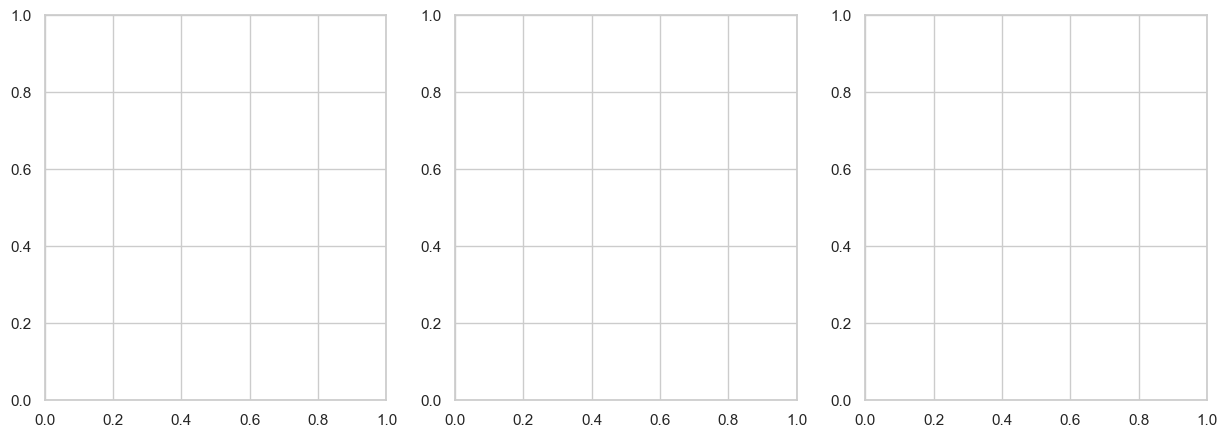

In [10]:
def display_images_by_area(area, num_images=6):
    """Display sample images from a specific area"""
    area_images = metadata_df[metadata_df['area'] == area]
    
    if len(area_images) == 0:
        print(f"No images found for area: {area}")
        return
    
    # Select random sample
    sample = area_images.sample(min(num_images, len(area_images)), random_state=42)
    
    # Create figure
    cols = 3
    rows = (len(sample) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(15, 5*rows))
    axes = axes.flatten() if rows > 1 else [axes]
    
    for idx, (_, row) in enumerate(sample.iterrows()):
        img_path = ROOT / row['relative_path']
        if img_path.exists():
            img = Image.open(img_path)
            axes[idx].imshow(img)
            axes[idx].set_title(f"{row['image_id']}", fontsize=10)
            axes[idx].axis('off')
        else:
            axes[idx].text(0.5, 0.5, 'Image not found', ha='center', va='center')
            axes[idx].axis('off')
    
    # Hide unused subplots
    for idx in range(len(sample), len(axes)):
        axes[idx].axis('off')
    
    plt.suptitle(f"Sample Images from {area} ({AREA_CODES.get(area, 'N/A')})", fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

# Create interactive widget
area_dropdown = widgets.Dropdown(
    options=list(AREA_CODES.keys()),
    value='DU-Shahbagh',
    description='Area:'
)

num_slider = widgets.IntSlider(
    value=6,
    min=3,
    max=12,
    step=3,
    description='Images:'
)

interact(display_images_by_area, area=area_dropdown, num_images=num_slider)
print("Use the dropdown to select an area and slider to choose number of images to display.")

## 8. Hyperparameter Tuning Visualization (Interactive)

In [11]:
if model_selection:
    best_extractor = model_selection.get('best_extractor', 'hog')
    cv_csv_path = OUTPUTS_DIR / f"cv-results-{best_extractor}.csv"
    
    if cv_csv_path.exists():
        cv_df = pd.read_csv(cv_csv_path)
        
        # Create interactive plot
        fig = px.line(
            cv_df,
            x='param_knn__n_neighbors',
            y='mean_test_macro_f1',
            color='param_pca__n_components',
            line_group='param_pca__n_components',
            markers=True,
            title=f'Hyperparameter Tuning: CV Macro-F1 vs k-neighbors ({best_extractor.upper()})',
            labels={
                'param_knn__n_neighbors': 'Number of Neighbors (k)',
                'mean_test_macro_f1': 'CV Macro-F1',
                'param_pca__n_components': 'PCA Components'
            },
            hover_data=['param_knn__weights', 'param_knn__metric']
        )
        fig.update_layout(height=500)
        fig.show()
        
        # Display best parameters
        best_result = next((r for r in model_selection['results'] if r['extractor'] == best_extractor), None)
        if best_result:
            print(f"\nBest Configuration for {best_extractor.upper()}:")
            print(f"  k: {best_result['best_params']['k']}")
            print(f"  PCA Components: {best_result['best_params']['pca_components']}")
            print(f"  Weights: {best_result['best_params']['weights']}")
            print(f"  Metric: {best_result['best_params']['metric']}")
            print(f"  CV Macro-F1: {best_result['cv_macro_f1']:.4f} ± {best_result['cv_std_macro_f1']:.4f}")
    else:
        print(f"CV results file not found for {best_extractor}")
else:
    print("Model selection results not available")


Best Configuration for HOG:
  k: 9
  PCA Components: 256
  Weights: distance
  Metric: cosine
  CV Macro-F1: 0.5170 ± 0.0369


## 9. Feature Extractor Comparison (Interactive Radar Chart)

In [12]:
if model_selection:
    # Prepare data for radar chart
    extractors = ['raw', 'hog', 'resnet']
    metrics_data = []
    
    for result in model_selection['results']:
        metrics_data.append({
            'Extractor': result['extractor'].upper(),
            'Accuracy': result['val_metrics']['accuracy'],
            'Macro-F1': result['val_metrics']['macro_f1'],
            'Weighted-F1': result['val_metrics']['weighted_f1'],
            'CV Macro-F1': result['cv_macro_f1']
        })
    
    df_radar = pd.DataFrame(metrics_data)
    
    # Create radar chart
    fig = go.Figure()
    
    categories = ['Accuracy', 'Macro-F1', 'Weighted-F1', 'CV Macro-F1']
    
    for idx, row in df_radar.iterrows():
        fig.add_trace(go.Scatterpolar(
            r=[row[cat] for cat in categories],
            theta=categories,
            fill='toself',
            name=row['Extractor']
        ))
    
    fig.update_layout(
        polar=dict(
            radialaxis=dict(
                visible=True,
                range=[0, 1]
            )
        ),
        title="Feature Extractor Comparison",
        height=500
    )
    fig.show()
else:
    print("Model selection results not available")

## 10. Misclassified Images Viewer (Interactive)

In [ ]:
if evaluation:
    # Load test predictions
    predictions_path = OUTPUTS_DIR / "test-predictions.csv"
    if predictions_path.exists():
        predictions_df = pd.read_csv(predictions_path)
        
        # Filter misclassified images
        misclassified = predictions_df[predictions_df['correct'] == False]
        
        print(f"Total misclassified images: {len(misclassified)}")
        
        def display_misclassified(start_idx=0, num_images=6):
            """Display a batch of misclassified images"""
            end_idx = min(start_idx + num_images, len(misclassified))
            batch = misclassified.iloc[start_idx:end_idx]
            
            if len(batch) == 0:
                print("No more misclassified images to display")
                return
            
            cols = 3
            rows = (len(batch) + cols - 1) // cols
            fig, axes = plt.subplots(rows, cols, figsize=(15, 5*rows))
            axes = axes.flatten() if rows > 1 else [axes]
            
            for idx, (_, row) in enumerate(batch.iterrows()):
                img_path = ROOT / row['relative_path']
                if img_path.exists():
                    img = Image.open(img_path)
                    axes[idx].imshow(img)
                    title = f"True: {row['label']} | Pred: {row['prediction']}"
                    if 'confidence' in row:
                        title += f"\nConf: {row['confidence']:.2f}"
                    axes[idx].set_title(title, fontsize=9)
                    axes[idx].axis('off')
                else:
                    axes[idx].text(0.5, 0.5, 'Image not found', ha='center', va='center')
                    axes[idx].axis('off')
            
            # Hide unused subplots
            for idx in range(len(batch), len(axes)):
                axes[idx].axis('off')
            
            plt.suptitle(f"Misclassified Test Images ({start_idx+1}-{end_idx} of {len(misclassified)})", 
                        fontsize=14, fontweight='bold')
            plt.tight_layout()
            plt.show()
        
        # Create interactive widget
        start_slider = widgets.IntSlider(
            value=0,
            min=0,
            max=max(0, len(misclassified) - 6),
            step=6,
            description='Start Index:'
        )
        
        num_slider = widgets.IntSlider(
            value=6,
            min=3,
            max=12,
            step=3,
            description='Images:'
        )
        
        interact(display_misclassified, start_idx=start_slider, num_images=num_slider)
        print("Use sliders to navigate through misclassified images.")
    else:
        print("Test predictions file not found")
else:
    print("Evaluation results not available")

Total misclassified images: 76


interactive(children=(IntSlider(value=0, description='Start Index:', max=70, step=6), IntSlider(value=6, descr…

Use sliders to navigate through misclassified images.


## 11. Area-wise Performance Summary (Interactive)

In [14]:
if evaluation and model_selection:
    # Combine validation and test per-class metrics
    val_per_class = model_selection.get('validation_per_class', {})
    test_per_class = evaluation['metrics']['per_class']
    
    comparison_data = []
    for label in evaluation['labels']:
        comparison_data.append({
            'Area Code': label,
            'Area': CODE_TO_AREA.get(label, label),
            'Val Precision': val_per_class.get(label, {}).get('precision', 0),
            'Val Recall': val_per_class.get(label, {}).get('recall', 0),
            'Val F1': val_per_class.get(label, {}).get('f1', 0),
            'Test Precision': test_per_class.get(label, {}).get('precision', 0),
            'Test Recall': test_per_class.get(label, {}).get('recall', 0),
            'Test F1': test_per_class.get(label, {}).get('f1', 0),
        })
    
    comp_df = pd.DataFrame(comparison_data)
    
    # Create comparison chart
    fig = make_subplots(
        rows=1, cols=3,
        subplot_titles=('Precision', 'Recall', 'F1-Score')
    )
    
    for idx, (metric, col_idx) in enumerate([('Precision', 1), ('Recall', 2), ('F1', 3)]):
        fig.add_trace(
            go.Bar(
                name='Validation',
                x=comp_df['Area Code'],
                y=comp_df[f'Val {metric}'],
                marker_color='#2a9d8f',
                showlegend=idx == 0
            ),
            row=1, col=col_idx
        )
        fig.add_trace(
            go.Bar(
                name='Test',
                x=comp_df['Area Code'],
                y=comp_df[f'Test {metric}'],
                marker_color='#e76f51',
                showlegend=idx == 0
            ),
            row=1, col=col_idx
        )
    
    fig.update_layout(
        title_text='Validation vs Test Performance by Area',
        height=500,
        barmode='group'
    )
    fig.show()
    
    # Display comparison table
    print("\nValidation vs Test Performance Comparison:")
    display(comp_df.style.format({
        'Val Precision': '{:.3f}',
        'Val Recall': '{:.3f}',
        'Val F1': '{:.3f}',
        'Test Precision': '{:.3f}',
        'Test Recall': '{:.3f}',
        'Test F1': '{:.3f}'
    }).hide(axis='index'))
else:
    print("Results not available")


Validation vs Test Performance Comparison:


Area Code,Area,Val Precision,Val Recall,Val F1,Test Precision,Test Recall,Test F1
AZN,Azimpur-Nilkhet,0.300,0.115,0.167,0.500,0.185,0.270
BRV,BaileyRoad-Viqarunnisa,0.450,0.429,0.439,0.667,0.190,0.296
BUP,Buet-Palashi,0.875,0.500,0.636,0.667,0.286,0.400
DMD,Dhanmondi,0.512,0.468,0.489,0.627,0.740,0.679
DUS,DU-Shahbagh,0.542,0.800,0.646,0.521,0.817,0.636
MUT,Mirpur-Uttara-Tejgaon,1.000,0.692,0.818,1.000,0.769,0.870


## 12. Summary and Key Insights

In [15]:
print("="*60)
print("WallVoice24BD Project Summary")
print("="*60)

print(f"\nDataset:")
print(f"  Total images: {len(metadata_df)}")
print(f"  Collection areas: {len(AREA_CODES)}")
print(f"  Area codes: {', '.join(AREA_CODES.values())}")

if splits:
    print(f"\nData Splits:")
    for split_name, split_df in splits.items():
        pct = len(split_df) / len(metadata_df) * 100
        print(f"  {split_name.capitalize()}: {len(split_df)} images ({pct:.1f}%)")

if model_selection:
    print(f"\nModel Selection:")
    print(f"  Best extractor: {model_selection['best_extractor'].upper()}")
    print(f"  CV folds: {model_selection['cv_folds']}")
    best_result = next((r for r in model_selection['results'] if r['extractor'] == model_selection['best_extractor']), None)
    if best_result:
        print(f"  Best CV Macro-F1: {best_result['cv_macro_f1']:.4f} ± {best_result['cv_std_macro_f1']:.4f}")
        print(f"  Validation Macro-F1: {best_result['val_metrics']['macro_f1']:.4f}")

if evaluation:
    print(f"\nTest Evaluation:")
    print(f"  Accuracy: {evaluation['metrics']['accuracy']:.4f} ({evaluation['metrics']['accuracy']*100:.1f}%)")
    print(f"  Macro-F1: {evaluation['metrics']['macro_f1']:.4f}")
    print(f"  Weighted-F1: {evaluation['metrics']['weighted_f1']:.4f}")
    print(f"  Misclassified: {evaluation['misclassified']} / {evaluation['n_test']}")

print("\n" + "="*60)
print("Interactive Features:")
print("  - All plots are interactive (zoom, pan, hover)")
print("  - Use dropdowns and sliders to explore data")
print("  - Click on legend items to toggle traces")
print("="*60)

WallVoice24BD Project Summary

Dataset:
  Total images: 1225
  Collection areas: 6
  Area codes: DUS, DMD, AZN, BRV, BUP, MUT

Data Splits:
  Train: 854 images (69.7%)
  Val: 186 images (15.2%)
  Test: 185 images (15.1%)

Model Selection:
  Best extractor: HOG
  CV folds: 5
  Best CV Macro-F1: 0.5170 ± 0.0369
  Validation Macro-F1: 0.5325

Test Evaluation:
  Accuracy: 0.5892 (58.9%)
  Macro-F1: 0.5252
  Weighted-F1: 0.5543
  Misclassified: 76 / 185

Interactive Features:
  - All plots are interactive (zoom, pan, hover)
  - Use dropdowns and sliders to explore data
  - Click on legend items to toggle traces
